# SnapKV Token Dropping Example with LMCache SDK
---

Long prompts create large KV caches that eat up GPU memory and limit how many 
requests fit in a batch, and a smaller batch means lower decode throughput. 
Token dropping shrinks each request's KV cache (in this example by half), so more
requests fits in a batch. This notebook shows improvement in decode 
throughput by 1.5-1.7x by using LMCache's SDK API that enables ML engineers get
a requests' KV, do optimizations such as token dropping, and put it back to use
during LLM serving.

Additionally, this example proves that the accuracy of generation is unaffected,
even improved, by token dropping.

Requirements:
* A small 10-lines modification is needed on vLLM's side to expose intermediate
  tensors to LMCache. Please do the setup steps outlined in 
  [README.md](./README.md)
* This experiment requires a GPU. To demonstrate how token dropping increases 
  the decoding batch size, adjust the GPU memory utilization together with the 
  number of requests. This example uses one GPU H200.

## Setup vLLM and LMCache server
Follow below instructions (1-4), then proceed to below Python cell.

**1. Start LMCache server first**

To enable query tensor transfer, we load the qstore server module with `--server-module '{"module_path": "lmcache.v1.multiprocess.plugin_modules.qstore"}'`.

```sh
lmcache server \
    --l1-size-gb 100 \
    --eviction-policy LRU \
    --chunk-size 544 \
    --port 6555 \
    --http-port 8080 \
    --no-l1-use-lazy \
    --server-module '{"module_path": "lmcache.v1.multiprocess.plugin_modules.qstore"}' \
    --eviction-trigger-watermark 0.95 \
    --supported-transfer-mode lmcache_driven \
    --separate-object-groups \
    --max-gpu-workers 8 \
    --runtime-plugin-config '{"sdk.kernel_block_size": 32}'
```

**2. Wait until LMCache server is ready**

```sh
curl -sf http://localhost:8080/healthcheck && echo " LMCache ready"
```

**3. Start vLLM once LMCache server is ready**

We keep vLLM's own KV cache memory small by `--gpu-memory-utilization 0.1` and
`--num-gpu-blocks-override 600` so that the prefilled KV is served from
LMCache, and the decode batch is limited by the KV capacity.
This ensures the decoding throughput improvement can be attributed entirely to
the  tokens dropped through LMCache.
vLLM's prefix cache is also reset between the baseline and token-dropping runs.

```sh
VLLM_SERVER_DEV_MODE=1 vllm serve Qwen/Qwen3.5-0.8B \
    --port 8000 \
    --served-model-name Qwen/Qwen3.5-0.8B \
    --enable-prefix-caching \
    --enforce-eager \
    --gpu-memory-utilization 0.1 \
    --no-enable-chunked-prefill \
    --max-model-len 32768 \
    --max-num-batched-tokens 1087 \
    --kv-transfer-config '{"kv_connector":"LMCacheMPConnector","kv_role":"kv_both","kv_connector_extra_config":{"lmcache.mp.port":6555,"lmcache.mp.transfer_intermediate_tensors":true,"lmcache.mp.q.ring_depth":50,"lmcache.mp.q.sw_size_tokens": 544,"lmcache.mp.save_decode_cache":true}}' \
    --trust-remote-code \
    --return-tokens-as-token-ids \
    --mamba-cache-mode align \
    --num-gpu-blocks-override 600
```

To enable query tensor transfer, pass 
`"lmcache.mp.transfer_intermediate_tensors":true` as an additional argument
to `--kv-transfer-config`. To adjust the QRingBuffer capacity, which holds
the query tensor temporarily before storing in L1, pass `"lmcache.mp.q.ring_depth"`
which defaults to 2 (2 means the QRingBuffer can hold the query tensors of 2
forward passes).

**4. Wait until vLLM is ready**

```sh
curl -sf http://localhost:8000/v1/models && echo " vLLM ready"
```

In [1]:
# SPDX-License-Identifier: Apache-2.0
"""End-to-end KV cache remapping driver for the SDK example."""

# Standard
from datasets import load_dataset
import math
import matplotlib.pyplot as plt
import sys
from transformers import AutoTokenizer, AutoConfig

# Third Party
import torch
import torch.nn.functional as F

# First Party
from lmcache.logging import init_logger
import lmcache.sdk as lmc_sdk
from lmcache.banner import print_banner_once
from utils import (
    rerotate_k_cache,
    make_post_completion,
    score_answers,
)

print_banner_once(sys.stdout)
logger = init_logger(__name__)

/home/rani/vllm/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[2026-11-12 13:10:47,926] LMCache INFO: torch_dev=<module 'torch.cuda' from '/home/rani/vllm/.venv/lib/python3.12/site-packages/torch/cuda/__init__.py'>, torch_device_type=cuda (_device_detect.py:311:lmcache.v1.platform._device_detect)
[2026-11-12 13:10:47,929] LMCache INFO: Auto-selected backend [cuda] for accelerator 'cuda' from candidate backends [cuda, rocm]. (__init__.py:160:lmcache.v1.platform)



 _     __  __    ____           _          
| |   |  \/  |  / ___|__ _  ___| |__   ___      LMCache v0.5.8.dev118 (gd7707981)
| |   | |\/| | | |   / _` |/ __| '_ \ / _ \     Website:  https://lmcache.ai/
| |___| |  | | | |__| (_| | (__| | | |  __/     Recipes:  https://docs.lmcache.ai/recipes
|_____|_|  |_|  \____\__,_|\___|_| |_|\___|     LinkedIn: https://www.linkedin.com/company/lmcache-lab
Set LMCACHE_DISABLE_BANNER=1 to hide this banner.



## Setting up hyperparameters

In [2]:
model_name = "Qwen/Qwen3.5-0.8B"
vllm_url = "http://localhost:8012"
lmcache_url = "http://localhost:8081"
lmcache_mq_url = "tcp://localhost:6556"
max_tokens = 2048
temperature = 0.0  # greedy decode so generated answers are deterministic and scorable
timeout = 60  # timeout for context retrieval (seconds)
trust_remote_code = True
decode_turns = 2  # prefill 1x followed by decode 2x
# first decode to show improvement from token dropping for prefilled prompt
# second decode to show additional improvement from dropping tokens generated
# during the first decode

## Configuring the model and LMCache endpoint

In [4]:
tokenizer = AutoTokenizer.from_pretrained(
    model_name, trust_remote_code=trust_remote_code
)
config = AutoConfig.from_pretrained(
    model_name, trust_remote_code=trust_remote_code
).get_text_config()
work_device = torch.device("cpu")
post_completion = make_post_completion(vllm_url, model_name, timeout)
ctx = lmc_sdk.kvcache.connect(
    url=lmcache_mq_url,
    http_url=lmcache_url,
    model_name=model_name,
    timeout=timeout,
)
qctx = lmc_sdk.qcache.connect(
    url=lmcache_mq_url,
    http_url=lmcache_url,
    model_name=model_name,
    timeout=timeout,
)
ctx.set_max_transfers(2)  # set max concurrent transfers to avoid RingStateError

[2026-11-12 13:11:55,599] LMCache INFO: Initialized LMCacheSDKContext with instance_id=3562344838785256653, model_name=Qwen/Qwen3.5-0.8B, chunk_size=544, kind=LMCacheSDKCacheKind.KV (context.py:243:lmcache.sdk.context)
[2026-11-12 13:11:57,007] LMCache INFO: Opened the Q ring of Qwen/Qwen3.5-0.8B##query: 6 layers x [140, 544, 2048], instance 3633347648850540253 (ring_mapping.py:239:lmcache.sdk.wrapper.ring_mapping)
[2026-11-12 13:11:57,009] LMCache INFO: Transferring Qwen/Qwen3.5-0.8B through vLLM's Q ring on cuda:5: 6684672 bytes per chunk object (context.py:476:lmcache.sdk.context)
[2026-11-12 13:11:57,025] LMCache INFO: Initialized LMCacheSDKContext with instance_id=2992877474734549749, model_name=Qwen/Qwen3.5-0.8B##query, chunk_size=544, kind=LMCacheSDKCacheKind.QUERY (context.py:243:lmcache.sdk.context)
[2026-11-12 13:11:57,029] LMCache INFO: Opened the Q ring of Qwen/Qwen3.5-0.8B##query: 6 layers x [140, 544, 2048], instance 3633347648850540253 (ring_mapping.py:239:lmcache.sdk.wr

## Constructing Prompt

In [5]:
prompts = []
answers = []
ds = load_dataset("raniayu/token-dropping-demo", split="train")
for i, example in enumerate(ds):
    prompt = tokenizer.encode(ds[i]["prompt"], return_tensors="pt").squeeze(0).tolist()
    prompts.append(prompt)
    answers.append(ds[i]["answer"])

print(f"Loaded {len(prompts)} prompts from the dataset.")
print(f"Total prompts length: {sum(len(p) for p in prompts)} tokens.")
print(f"Mean prompt length: {sum(len(p) for p in prompts) / len(prompts):.2f} tokens.")
print(f"Max prompt length: {max(len(p) for p in prompts)} tokens.")
print(f"Min prompt length: {min(len(p) for p in prompts)} tokens.")

Loaded 30 prompts from the dataset.
Total prompts length: 431247 tokens.
Mean prompt length: 14374.90 tokens.
Max prompt length: 17821 tokens.
Min prompt length: 10329 tokens.


## Baseline (without token dropping)

In [10]:
batch = lmc_sdk.batch.LMCacheBatchedStream()
for i, prompt in enumerate(prompts):
    request = lmc_sdk.request.create_request(
        contexts=[ctx, qctx],
        post_completion=post_completion,
        prompt_token_ids=prompt,
    )
    batch.add(request)
results = batch.prefill(
    sampling_params={"max_tokens": 1, "temperature": 1.0, "ignore_eos": True}
)
results.emit()

logger.info("\n\n")

texts_per_round, lengths_per_round = [], []
for r in range(decode_turns):
    results = batch.decode(
        sampling_params={
            "max_tokens": max_tokens,
            "temperature": temperature,
            "ignore_eos": True,
        }
    )
    results.emit()
    texts_per_round.append([s.output_text for s in batch.request_streams.values()])

before_drop_data = results.to_dict()
before_texts = texts_per_round[-1]

[2026-11-12 13:26:23,951] LMCache INFO: 

 (4248204430.py:14:__main__)


======================= Batched Stream Metrics (prefill) =======================
-------------------------------- Configuration ---------------------------------
Number of Request Streams:                                                    30
----------------------------------- Results ------------------------------------
Total Duration (s):                                                        28.80
Total Input Tokens:                                                       431247
Input Throughput (tokens/s):                                            14975.24
======================= Batched Stream Metrics (decode) ========================
-------------------------------- Configuration ---------------------------------
Number of Request Streams:                                                    30
----------------------------------- Results ------------------------------------
Total Duration (s):                                                       120.94
Total Output Tokens:        

## Clear LMCache

In [9]:
!curl -X POST {lmcache_url}/cache/clear -H "Content-Type: application/json" -d '{{"tier": "l1", "force": true}}'
!curl -X POST {vllm_url}/reset_prefix_cache

{"status":"ok","cleared":{"tier":"l1"}}

## With Token Dropping

In [7]:
CUDA_VISIBLE_DEVICES = "0"

snapkv_window_size = 64
snapkv_drop_ratio = 0.5
snapkv_kernel_size = 5
snapkv_pooling = "avgpool"


def _normalize_q_tensor(q_tensor: torch.Tensor) -> torch.Tensor:
    """Return q as [num_layers, T, num_q_heads * head_size]."""
    if q_tensor.ndim == 4:
        if q_tensor.shape[0] != 1:
            raise ValueError(f"expected q_tensor first dim 1, got {q_tensor.shape}")
        return q_tensor[0]
    if q_tensor.ndim == 3:
        return q_tensor
    raise ValueError(f"expected q_tensor 3D or 4D, got {q_tensor.shape}")


def _snapkv_layer_scores(
    k_flat: torch.Tensor,
    q_flat: torch.Tensor,
    *,
    seq_len: int,
    window_size: int,
    kernel_size: int,
    pooling: str,
    num_kv_heads: int,
    num_q_heads: int,
    head_size: int,
    device: torch.device,
) -> torch.Tensor:
    """Return one importance score per non-window past token."""
    if num_q_heads % num_kv_heads != 0:
        raise ValueError(
            f"num_q_heads ({num_q_heads}) must be divisible by "
            f"num_kv_heads ({num_kv_heads})"
        )

    groups = num_q_heads // num_kv_heads
    past_len = seq_len - window_size

    k = k_flat[:seq_len].to(device=device, dtype=torch.float32)
    q = q_flat.to(device=device, dtype=torch.float32)

    k = k.reshape(seq_len, num_kv_heads, head_size).permute(1, 0, 2)
    q = q.reshape(q.shape[0], num_kv_heads, groups, head_size)

    q_recent = q[-window_size:].permute(1, 2, 0, 3)

    attn = torch.einsum("kgwd,ktd->kgwt", q_recent, k) / math.sqrt(head_size)

    causal = torch.triu(
        torch.full(
            (window_size, window_size),
            torch.finfo(attn.dtype).min,
            dtype=attn.dtype,
            device=device,
        ),
        diagonal=1,
    )
    attn[..., -window_size:] += causal

    attn = F.softmax(attn, dim=-1, dtype=torch.float32)
    past_scores = attn[..., :past_len].sum(dim=-2)

    channels = past_scores.reshape(1, -1, past_len)
    if pooling == "avgpool":
        channels = F.avg_pool1d(
            channels, kernel_size=kernel_size, padding=kernel_size // 2, stride=1
        )
    elif pooling == "maxpool":
        channels = F.max_pool1d(
            channels, kernel_size=kernel_size, padding=kernel_size // 2, stride=1
        )
    else:
        raise ValueError(f"Pooling method not supported: {pooling}")

    return channels[..., :past_len].reshape(-1, past_len).mean(dim=0)


def drop_tokens_fn(
    tensors: dict[lmc_sdk.context.LMCacheSDKCacheKind, torch.Tensor],
    token_source: list[int],
) -> tuple[torch.Tensor, list[int]]:
    """SnapKV token dropping: keep top-scored past tokens plus the last window."""
    q_tensor = tensors[lmc_sdk.context.LMCacheSDKCacheKind.QUERY]
    kv_tensor = tensors[lmc_sdk.context.LMCacheSDKCacheKind.KV]

    q_by_layer = _normalize_q_tensor(q_tensor)

    q_len = q_by_layer.shape[1]
    kv_len = kv_tensor.shape[2]
    logger.info(
        "modify: KV covers %d tokens, decoded segment [%d, %d), query window %d rows",
        kv_len,
        tensors.segment_start_token_id,
        kv_len,
        q_len,
    )

    seq_len = min(kv_tensor.shape[2], len(token_source))
    if q_by_layer.shape[1] < snapkv_window_size:
        raise ValueError(
            f"Q window has {q_by_layer.shape[1]} rows, need >= {snapkv_window_size}"
        )

    num_q_heads = config.num_attention_heads
    num_kv_heads = getattr(config, "num_key_value_heads", num_q_heads)
    head_dim = getattr(config, "head_dim", config.hidden_size // num_q_heads)

    if kv_tensor.shape[-1] != num_kv_heads * head_dim:
        raise ValueError(
            f"KV hidden dim {kv_tensor.shape[-1]} != {num_kv_heads * head_dim}"
        )
    if q_by_layer.shape[-1] != num_q_heads * head_dim:
        raise ValueError(
            f"Q hidden dim {q_by_layer.shape[-1]} != {num_q_heads * head_dim}"
        )

    past_len = seq_len - snapkv_window_size
    if past_len <= 0:
        raise ValueError(
            f"seq_len ({seq_len}) must exceed window ({snapkv_window_size})"
        )

    # do token dropping only on the newly decoded tokens
    past_start = tensors.segment_start_token_id
    if not 0 <= past_start <= past_len:
        raise ValueError(
            f"decoded segment start ({past_start}) inconsistent with "
            f"seq_len ({seq_len})"
        )
    new_len = seq_len - past_start
    total_keep_new = int(round(new_len * (1 - snapkv_drop_ratio)))
    keep_past = max(0, min(total_keep_new - snapkv_window_size, past_len - past_start))

    # # Total tokens to retain, including recent window here
    # total_keep = int(round(seq_len * (1 - snapkv_drop_ratio)))
    # keep_past = max(0, min(total_keep - snapkv_window_size, past_len))

    scores = torch.zeros(past_len, dtype=torch.float32, device=work_device)
    for layer in range(kv_tensor.shape[1]):
        scores += _snapkv_layer_scores(
            kv_tensor[0, layer],
            q_by_layer[layer],
            seq_len=seq_len,
            window_size=snapkv_window_size,
            kernel_size=snapkv_kernel_size,
            pooling=snapkv_pooling,
            num_kv_heads=num_kv_heads,
            num_q_heads=num_q_heads,
            head_size=head_dim,
            device=work_device,
        )
    scores /= kv_tensor.shape[1]

    # past_keep = torch.topk(scores, k=keep_past, largest=True).indices.sort().values
    # last_window = torch.arange(past_len, seq_len, device=work_device)
    # keep_idx = torch.cat([past_keep, last_window]).to(dtype=torch.long)
    # # keep_idx = torch.arange(seq_len, device=work_device)
    cand_scores = scores[past_start:]
    past_keep = (
        torch.topk(cand_scores, k=keep_past, largest=True).indices.sort().values
        + past_start
    )
    protected = torch.arange(past_start, device=work_device)
    last_window = torch.arange(past_len, seq_len, device=work_device)
    keep_idx = torch.cat([protected, past_keep, last_window]).to(dtype=torch.long)

    keep_idx_cpu = keep_idx.cpu()
    kept_ids = [token_source[i] for i in keep_idx_cpu.tolist()]

    e_kv = rerotate_k_cache(
        kv_tensor[:, :, keep_idx_cpu, :].clone().to(work_device),
        old_positions=keep_idx,
        new_positions=torch.arange(keep_idx.numel(), device=work_device),
        model_config=config,
    )

    logger.info("compacted %d/%d tokens.", e_kv.shape[2], kv_tensor.shape[2])

    return e_kv.cpu(), kept_ids

In [8]:
stream_ids = []

batch = lmc_sdk.batch.LMCacheBatchedStream()
for i, prompt in enumerate(prompts):
    request = lmc_sdk.request.create_request(
        contexts=[ctx, qctx],
        post_completion=post_completion,
        prompt_token_ids=prompt,
    )
    batch.add(request)
    stream_ids.append(request.request_stream_id)

results = batch.prefill(
    sampling_params={"max_tokens": 1, "temperature": 1.0, "ignore_eos": True}
)
results.emit()

texts_per_round, lengths_per_round = [], []
for r in range(decode_turns):
    batch.modify(drop_tokens_fn).emit()
    lengths_per_round.append([len(s.tokens) for s in batch.request_streams.values()])
    logger.info("round %d kept: %s", r, lengths_per_round[-1])

    results = batch.decode(
        sampling_params={
            "max_tokens": max_tokens,
            "temperature": temperature,
            "ignore_eos": True,
        }
    )
    results.emit()
    texts_per_round.append([s.output_text for s in batch.request_streams.values()])

after_drop_data = results.to_dict()
after_texts = texts_per_round[-1]

======================= Batched Stream Metrics (prefill) =======================
-------------------------------- Configuration ---------------------------------
Number of Request Streams:                                                    30
----------------------------------- Results ------------------------------------
Total Duration (s):                                                        28.81
Total Input Tokens:                                                       431247
Input Throughput (tokens/s):                                            14968.32


[2026-11-12 13:13:05,470] LMCache INFO: modify: KV covers 10336 tokens, decoded segment [0, 10336), query window 544 rows (3888086228.py:94:__main__)
[2026-11-12 13:13:05,472] LMCache INFO: modify: KV covers 9792 tokens, decoded segment [0, 9792), query window 544 rows (3888086228.py:94:__main__)
[2026-11-12 13:13:05,552] LMCache INFO: modify: KV covers 10880 tokens, decoded segment [0, 10880), query window 544 rows (3888086228.py:94:__main__)
[2026-11-12 13:13:05,555] LMCache INFO: modify: KV covers 10880 tokens, decoded segment [0, 10880), query window 544 rows (3888086228.py:94:__main__)
[2026-11-12 13:13:05,620] LMCache INFO: modify: KV covers 10880 tokens, decoded segment [0, 10880), query window 544 rows (3888086228.py:94:__main__)
[2026-11-12 13:13:05,628] LMCache INFO: modify: KV covers 11424 tokens, decoded segment [0, 11424), query window 544 rows (3888086228.py:94:__main__)
[2026-11-12 13:13:05,680] LMCache INFO: modify: KV covers 11424 tokens, decoded segment [0, 11424), qu

======================== Batched Stream Modify Metrics =========================
----------------------------------- Results ------------------------------------
Total Duration (s):                                                        11.21
======================= Batched Stream Metrics (decode) ========================
-------------------------------- Configuration ---------------------------------
Number of Request Streams:                                                    30
----------------------------------- Results ------------------------------------
Total Duration (s):                                                        82.90
Total Output Tokens:                                                       61439
Decode Throughput (tokens/s):                                             741.14


[2026-11-12 13:14:37,025] LMCache INFO: modify: KV covers 7072 tokens, decoded segment [4896, 7072), query window 544 rows (3888086228.py:94:__main__)
[2026-11-12 13:14:37,042] LMCache INFO: modify: KV covers 7072 tokens, decoded segment [4896, 7072), query window 544 rows (3888086228.py:94:__main__)
[2026-11-12 13:14:37,084] LMCache INFO: modify: KV covers 7072 tokens, decoded segment [5440, 7072), query window 544 rows (3888086228.py:94:__main__)
[2026-11-12 13:14:37,095] LMCache INFO: modify: KV covers 7616 tokens, decoded segment [5440, 7616), query window 544 rows (3888086228.py:94:__main__)
[2026-11-12 13:14:37,117] LMCache INFO: modify: KV covers 7616 tokens, decoded segment [5440, 7616), query window 544 rows (3888086228.py:94:__main__)
[2026-11-12 13:14:37,137] LMCache INFO: modify: KV covers 7616 tokens, decoded segment [5440, 7616), query window 544 rows (3888086228.py:94:__main__)
[2026-11-12 13:14:37,159] LMCache INFO: modify: KV covers 7616 tokens, decoded segment [5440, 

======================== Batched Stream Modify Metrics =========================
----------------------------------- Results ------------------------------------
Total Duration (s):                                                         6.85
======================= Batched Stream Metrics (decode) ========================
-------------------------------- Configuration ---------------------------------
Number of Request Streams:                                                    30
----------------------------------- Results ------------------------------------
Total Duration (s):                                                        79.52
Total Output Tokens:                                                       61410
Decode Throughput (tokens/s):                                             772.25


### Accuracy

In [11]:
before_correct, total, before_map = score_answers(answers, before_texts)
after_correct, total, after_map = score_answers(answers, after_texts)
logger.info(
    "Baseline (no drop): %s/%s correct (%.1f%%)",
    before_correct,
    total,
    100 * before_correct / total,
)
logger.info(
    "Token dropping: %s/%s correct (%.1f%%)",
    after_correct,
    total,
    100 * after_correct / total,
)

[2026-11-12 13:32:50,704] LMCache INFO: Baseline (no drop): 7/30 correct (23.3%) (234422767.py:3:__main__)
[2026-11-12 13:32:50,706] LMCache INFO: Token dropping: 5/30 correct (16.7%) (234422767.py:9:__main__)


## Result Plot

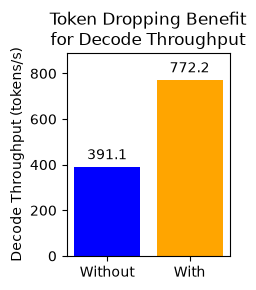

In [12]:
labels = ["Without", "With"]
data = [
    before_drop_data["metrics"]["results"]["output_tput"],
    after_drop_data["metrics"]["results"]["output_tput"],
]

fig, ax = plt.subplots(figsize=(2.5, 3))
bars = ax.bar(labels, data, color=["blue", "orange"])
ax.bar_label(bars, fmt="%.1f", padding=3)
ax.set_ylabel("Decode Throughput (tokens/s)")
ax.set_title("Token Dropping Benefit\nfor Decode Throughput")
ax.margins(y=0.15)
plt.tight_layout()
plt.show()

## Close both contexts

In [13]:
# Only close the context when done.
ctx.close()
qctx.close()